In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.NaN = np.nan

# Instrumente de preprocesare si reducere a dimensionalitatii
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

# Algoritmi de clusterizare si metrici de evaluare
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

# Biblioteci pentru vizualizari 3D(Bonus)
import plotly.express as px
import plotly.graph_objects as go

# Setari pentru grafice
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10

print("Toate bibliotecile s-au încărcat")

Toate bibliotecile s-au încărcat


Pregătirea Datelor, Scalarea și Reducerea Dimensionalității (PCA)

Pentru a antrena modelele K-Means:
1. Încărcăm setul de date curățat `AmesHousing_cleaned.csv` și eliminăm eventualii outlieri majori (`Gr Liv Area <= 4000`).
2. Codificăm variabilele categorice folosind One-Hot Encoding (`pd.get_dummies(drop_first=True)`).
3. Pregătim datele scalate prin două metode:
   - Min-Max Scaling (scalare în intervalul $[0, 1]$).
   - StandardScaler (recomandarea pentru PCA: medie 0 și varianță 1).
4. Aplicăm PCA pentru a păstra cele 4 praguri cerute de varianță explicată: 98%, 95%, 90% și 80%.

In [3]:
try:
    df = pd.read_csv('data/AmesHousing_cleaned.csv')
    if len(df.columns) == 1:
        df = pd.read_csv('data/AmesHousing_cleaned.csv', sep='\t')
except Exception:
    df = pd.read_csv('data/AmesHousing_cleaned.csv', sep='\t')

df.columns = df.columns.str.strip()

# Identificam coloanele principale
gr_liv_candidates = [c for c in df.columns if 'liv' in c.lower() and 'area' in c.lower()]
price_candidates = [c for c in df.columns if 'sale' in c.lower() and 'price' in c.lower()]

gr_liv_col = gr_liv_candidates[0]
sale_price_col = price_candidates[0]

# Filtrare outlieri
df = df[df[gr_liv_col] <= 4000].copy()

# Salvam etichetele de pret din L2 (cele 6 categorii qcut) pentru Bonus b
df['Price_Class_L2'] = pd.qcut(df[sale_price_col], q=6, labels=[0, 1, 2, 3, 4, 5])
price_classes_l2 = df['Price_Class_L2'].astype(int).values

# Separam atributele de invatare nesupervizata (excludem pretul si clasa sa)
X_raw = df.drop(columns=[sale_price_col, 'Price_Class_L2'])

# 2. One-Hot Encoding pentru variabilele categorice
X_encoded = pd.get_dummies(X_raw, drop_first=True)

# Imputare preventiva pentru valori lipsa cu mediana
X_encoded = X_encoded.fillna(X_encoded.median())

print(f"Dataset pregatit. Numar observatii: {X_encoded.shape[0]}, Numar atribute initiale codificate: {X_encoded.shape[1]}")

# 3. Scalari: Min-Max si StandardScaler
scaler_minmax = MinMaxScaler()
X_minmax = scaler_minmax.fit_transform(X_encoded)

scaler_std = StandardScaler()
X_std = scaler_std.fit_transform(X_encoded)

# 4. Reducerea dimensionalitatii prin PCA pe cele 4 praguri de varianta
thresholds = [0.98, 0.95, 0.90, 0.80]
pca_datasets_minmax = {}
pca_models_minmax = {}

print("Rezultate reducere PCA (Min-Max Scaling)")
for t in thresholds:
    pca = PCA(n_components=t, random_state=42)
    X_pca = pca.fit_transform(X_minmax)
    pca_datasets_minmax[t] = X_pca
    pca_models_minmax[t] = pca
    print(f"Prag varianta: {int(t*100)}% -> Numar componente principale retinute: {X_pca.shape[1]}")

# Generam si setul pe StandardScaler pentru comparatia ceruta
pca_datasets_std = {}
pca_models_std = {}
for t in thresholds:
    pca_s = PCA(n_components=t, random_state=42)
    pca_datasets_std[t] = pca_s.fit_transform(X_std)
    pca_models_std[t] = pca_s

Dataset pregatit. Numar observatii: 2925, Numar atribute initiale codificate: 225
Rezultate reducere PCA (Min-Max Scaling)
Prag varianta: 98% -> Numar componente principale retinute: 122
Prag varianta: 95% -> Numar componente principale retinute: 90
Prag varianta: 90% -> Numar componente principale retinute: 66
Prag varianta: 80% -> Numar componente principale retinute: 40


 **Pasul 2: Determinarea Numărului Optim de Clustere (Elbow Method & Silhouette Analysis)**

Pentru a stabili numărul optim de clustere (k) fără etichete supervizate, rulăm K-Means pe un interval de $k \in [2, 10]$ pentru cele 4 praguri de varianță PCA (98%, 95%, 90%, 80%):

1. Elbow Method - WCSS / Inertia:
   - Măsoară suma pătratelor distanțelor dintre fiecare punct și centroidul clusterului său.
   - Căutăm punctul de inflexiune („cotul”) dincolo de care scăderea inerției devine marginală.

2. Silhouette Score:
   - Măsoară cât de apropiat este un punct de propriul cluster comparativ cu cel mai apropiat cluster vecin. Valorile sunt în intervalul $[-1, 1]$ (valori mai mari $\rightarrow$ separare mai clară).
   - Analizăm media scorurilor și graficele siluetă pe fiecare cluster pentru a evita clusterele dezechilibrate sau cu coeficienți negativi.

Calculare K-Means (Elbow & Silhouette) pentru cele 4 praguri de varianta...


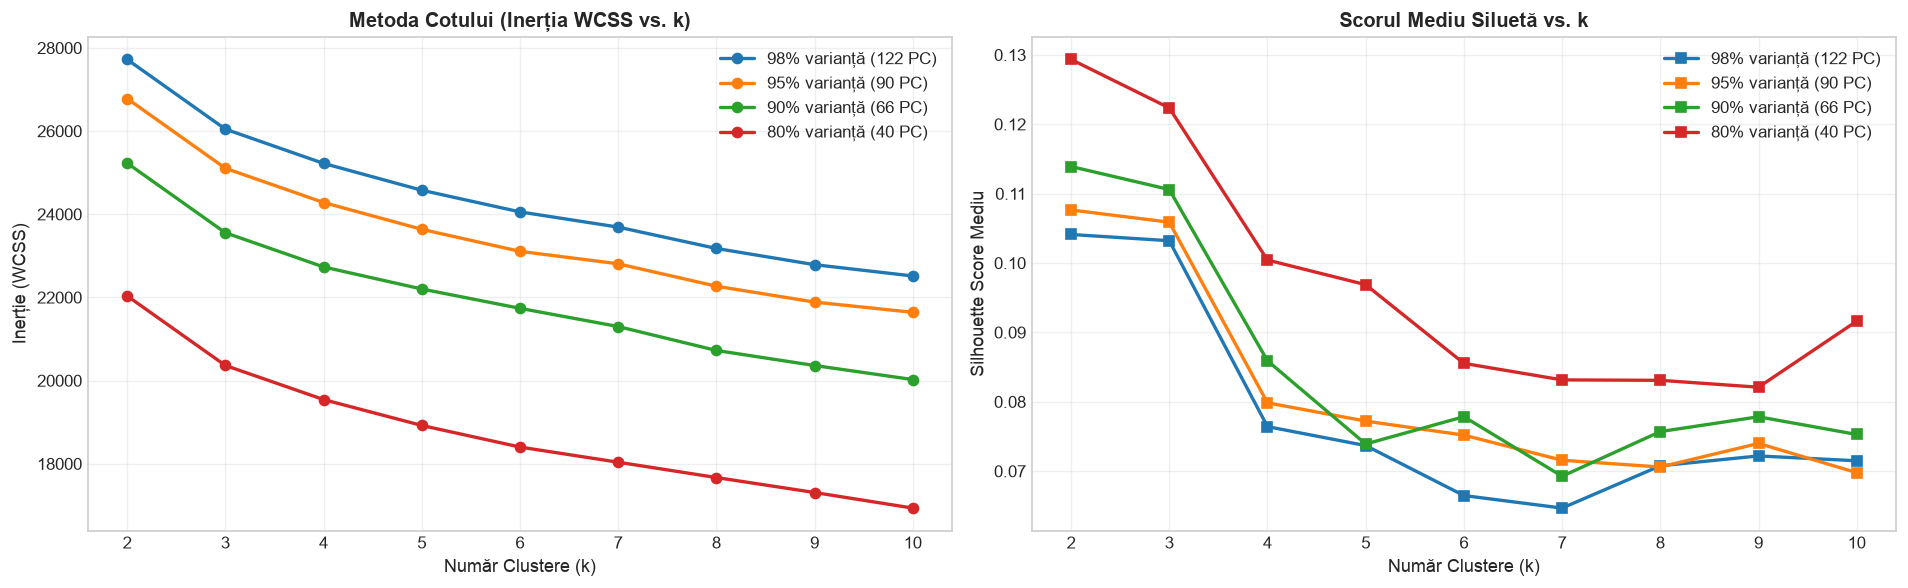


TABEL SCORURI MEDII SILUETĂ (Min-Max Scaling)
      98% Var  95% Var  90% Var  80% Var
k=2    0.1041   0.1076   0.1139   0.1293
k=3    0.1032   0.1059   0.1106   0.1224
k=4    0.0764   0.0799   0.0859   0.1004
k=5    0.0737   0.0772   0.0739   0.0969
k=6    0.0665   0.0752   0.0779   0.0855
k=7    0.0647   0.0716   0.0693   0.0832
k=8    0.0708   0.0706   0.0757   0.0831
k=9    0.0722   0.0740   0.0778   0.0821
k=10   0.0715   0.0698   0.0753   0.0916


In [4]:
k_range = list(range(2, 11))
inertia_dict = {t: [] for t in thresholds}
silhouette_dict = {t: [] for t in thresholds}

print("Calculare K-Means (Elbow & Silhouette) pentru cele 4 praguri de varianta...")

for t in thresholds:
    X_curr = pca_datasets_minmax[t]
    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = kmeans.fit_predict(X_curr)
        inertia_dict[t].append(kmeans.inertia_)
        score = silhouette_score(X_curr, labels)
        silhouette_dict[t].append(score)

# 1. Vizualizare: Graficul Metodei Elbow si Scorurile Silhouette
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

colors_thresh = {0.98: '#1f77b4', 0.95: '#ff7f0e', 0.90: '#2ca02c', 0.80: '#d62728'}

# Curba Elbow (Inertia)
for t in thresholds:
    axes[0].plot(k_range, inertia_dict[t], marker='o', lw=2, color=colors_thresh[t],
                 label=f'{int(t*100)}% varianță ({pca_datasets_minmax[t].shape[1]} PC)')
axes[0].set_title('Metoda Cotului (Inerția WCSS vs. k)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Număr Clustere (k)', fontsize=11)
axes[0].set_ylabel('Inerție (WCSS)', fontsize=11)
axes[0].set_xticks(k_range)
axes[0].legend()
axes[0].grid(alpha=0.3)

# Curba Silhouette Score
for t in thresholds:
    axes[1].plot(k_range, silhouette_dict[t], marker='s', lw=2, color=colors_thresh[t],
                 label=f'{int(t*100)}% varianță ({pca_datasets_minmax[t].shape[1]} PC)')
axes[1].set_title('Scorul Mediu Siluetă vs. k', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Număr Clustere (k)', fontsize=11)
axes[1].set_ylabel('Silhouette Score Mediu', fontsize=11)
axes[1].set_xticks(k_range)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 2. Tabel sintetic al valorilor medii Silhouette
df_silhouette = pd.DataFrame(silhouette_dict, index=[f'k={k}' for k in k_range])
df_silhouette.columns = [f'{int(t*100)}% Var' for t in thresholds]
print("\n" + "="*50)
print("TABEL SCORURI MEDII SILUETĂ (Min-Max Scaling)")
print("="*50)
print(df_silhouette.round(4))

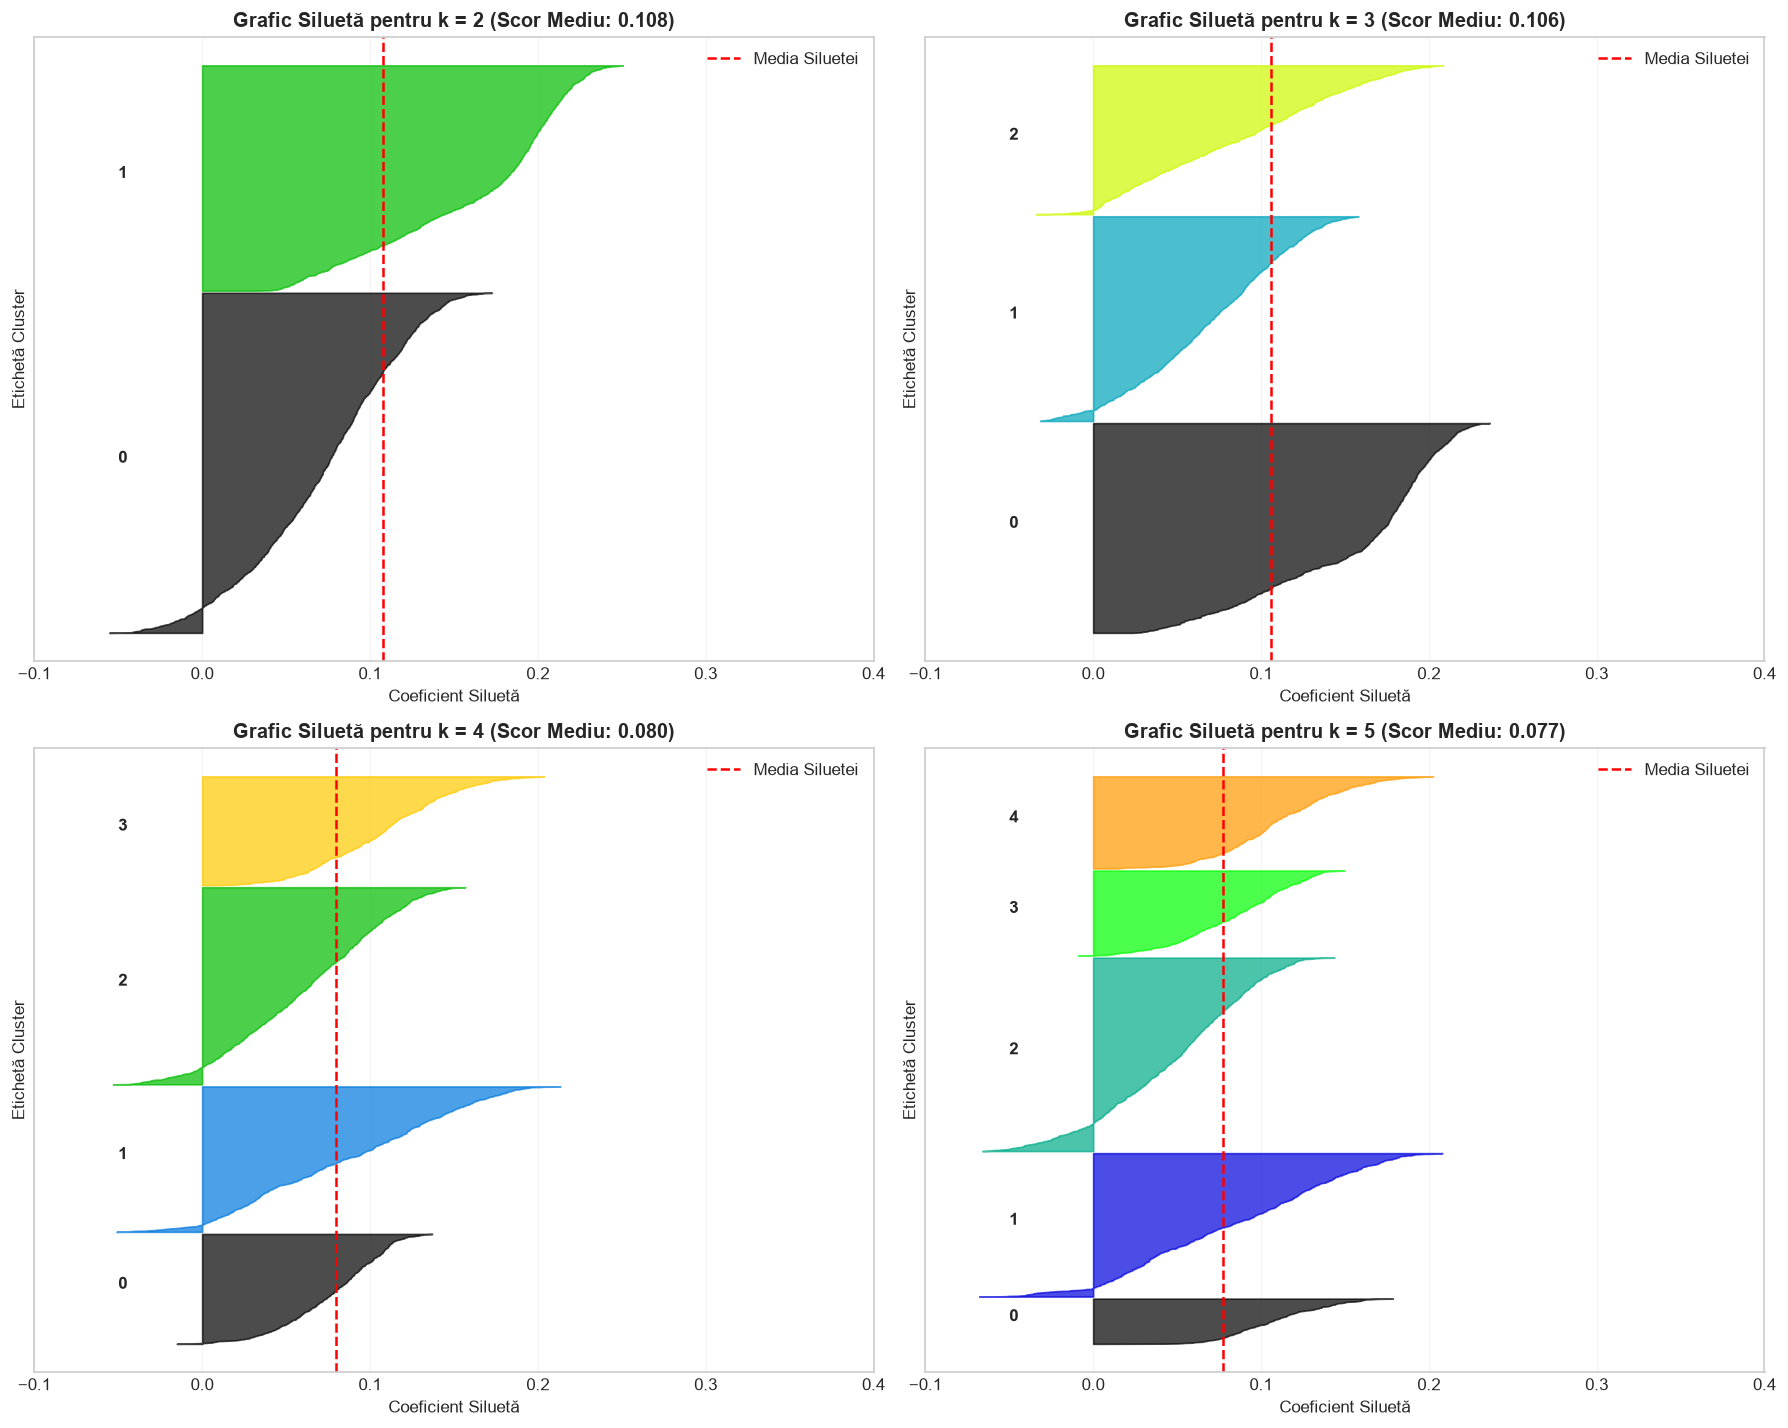

In [5]:
import matplotlib.cm as cm

# Trasarea profilului silueta detaliat pentru k in [2, 3, 4, 5] pe pragul de 95% varianta
X_eval = pca_datasets_minmax[0.95]
eval_k_values = [2, 3, 4, 5]

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.flatten()

for idx, k in enumerate(eval_k_values):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_eval)
    
    silhouette_avg = silhouette_score(X_eval, cluster_labels)
    sample_silhouette_values = silhouette_samples(X_eval, cluster_labels)
    
    ax = axes[idx]
    y_lower = 10
    
    for i in range(k):
        ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
        ith_cluster_silhouette_values.sort()
        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i
        
        color = cm.nipy_spectral(float(i) / k)
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_silhouette_values,
                         facecolor=color, edgecolor=color, alpha=0.7)
        ax.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i), fontsize=10, fontweight='bold')
        y_lower = y_upper + 10
        
    ax.set_title(f'Grafic Siluetă pentru k = {k} (Scor Mediu: {silhouette_avg:.3f})', fontweight='bold')
    ax.set_xlabel('Coeficient Siluetă')
    ax.set_ylabel('Etichetă Cluster')
    
    # Linia rosie punctata arata media globala
    ax.axvline(x=silhouette_avg, color="red", linestyle="--", lw=1.5, label='Media Siluetei')
    ax.set_yticks([])
    ax.set_xlim([-0.1, 0.4])
    ax.legend(loc="upper right")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

**Interpretarea Rezultatelor: Alegerea Numărului Optim de Clustere (k)**

1. **Analiza Elbow Curve):**
   - Pentru toate cele 4 praguri de varianță (98%, 95%, 90%, 80%), inerția (WCSS) scade vertiginos între $k=2$ și $k=4$, după care panta devine mult mai lină. Punctul de „cot” se situează la $k=3$ sau $k=4$.
   - Se observă că inerția totală este cu atât mai mică cu cât reținem mai puțină varianță (ex. la 80% avem doar 40 de componente, deci distanțele euclidiene însumate sunt mai mici în valoare absolută).

2. **Analiza Coeficienților Silhouette:**
   - Cel mai mare scor mediu silhouette se atinge la $k=2$ (~0.108) și $k=3$ (~0.106 pe 95% varianță).
   - Privind profilul detaliat al fiecărui cluster (Silhouette Plots):
     - La $k=2$, datele sunt împărțite în două macro-segmente, dar separarea este prea brută pentru o analiză imobiliară utilă.
     - La $k=3$, toate cele 3 clustere depășesc linia roșie a mediei globale și au dimensiuni echilibrate, cu grosimi consistente și fără valori negative semnificative.
     - La $k=4$ și $k=5$, apar clustere mici, fragmentate, iar clusterul 1 și 2 încep să aibă instanțe cu coeficienți negativi (semn de suprapunere / confuzie între clustere).

Concluzie: Valoarea **$k = 3$** (sau secundar $k = 4$) reprezintă compromisul ideal între robustețea matematică a coeziunii și utilitatea practică pentru segmentarea pieței imobiliare.

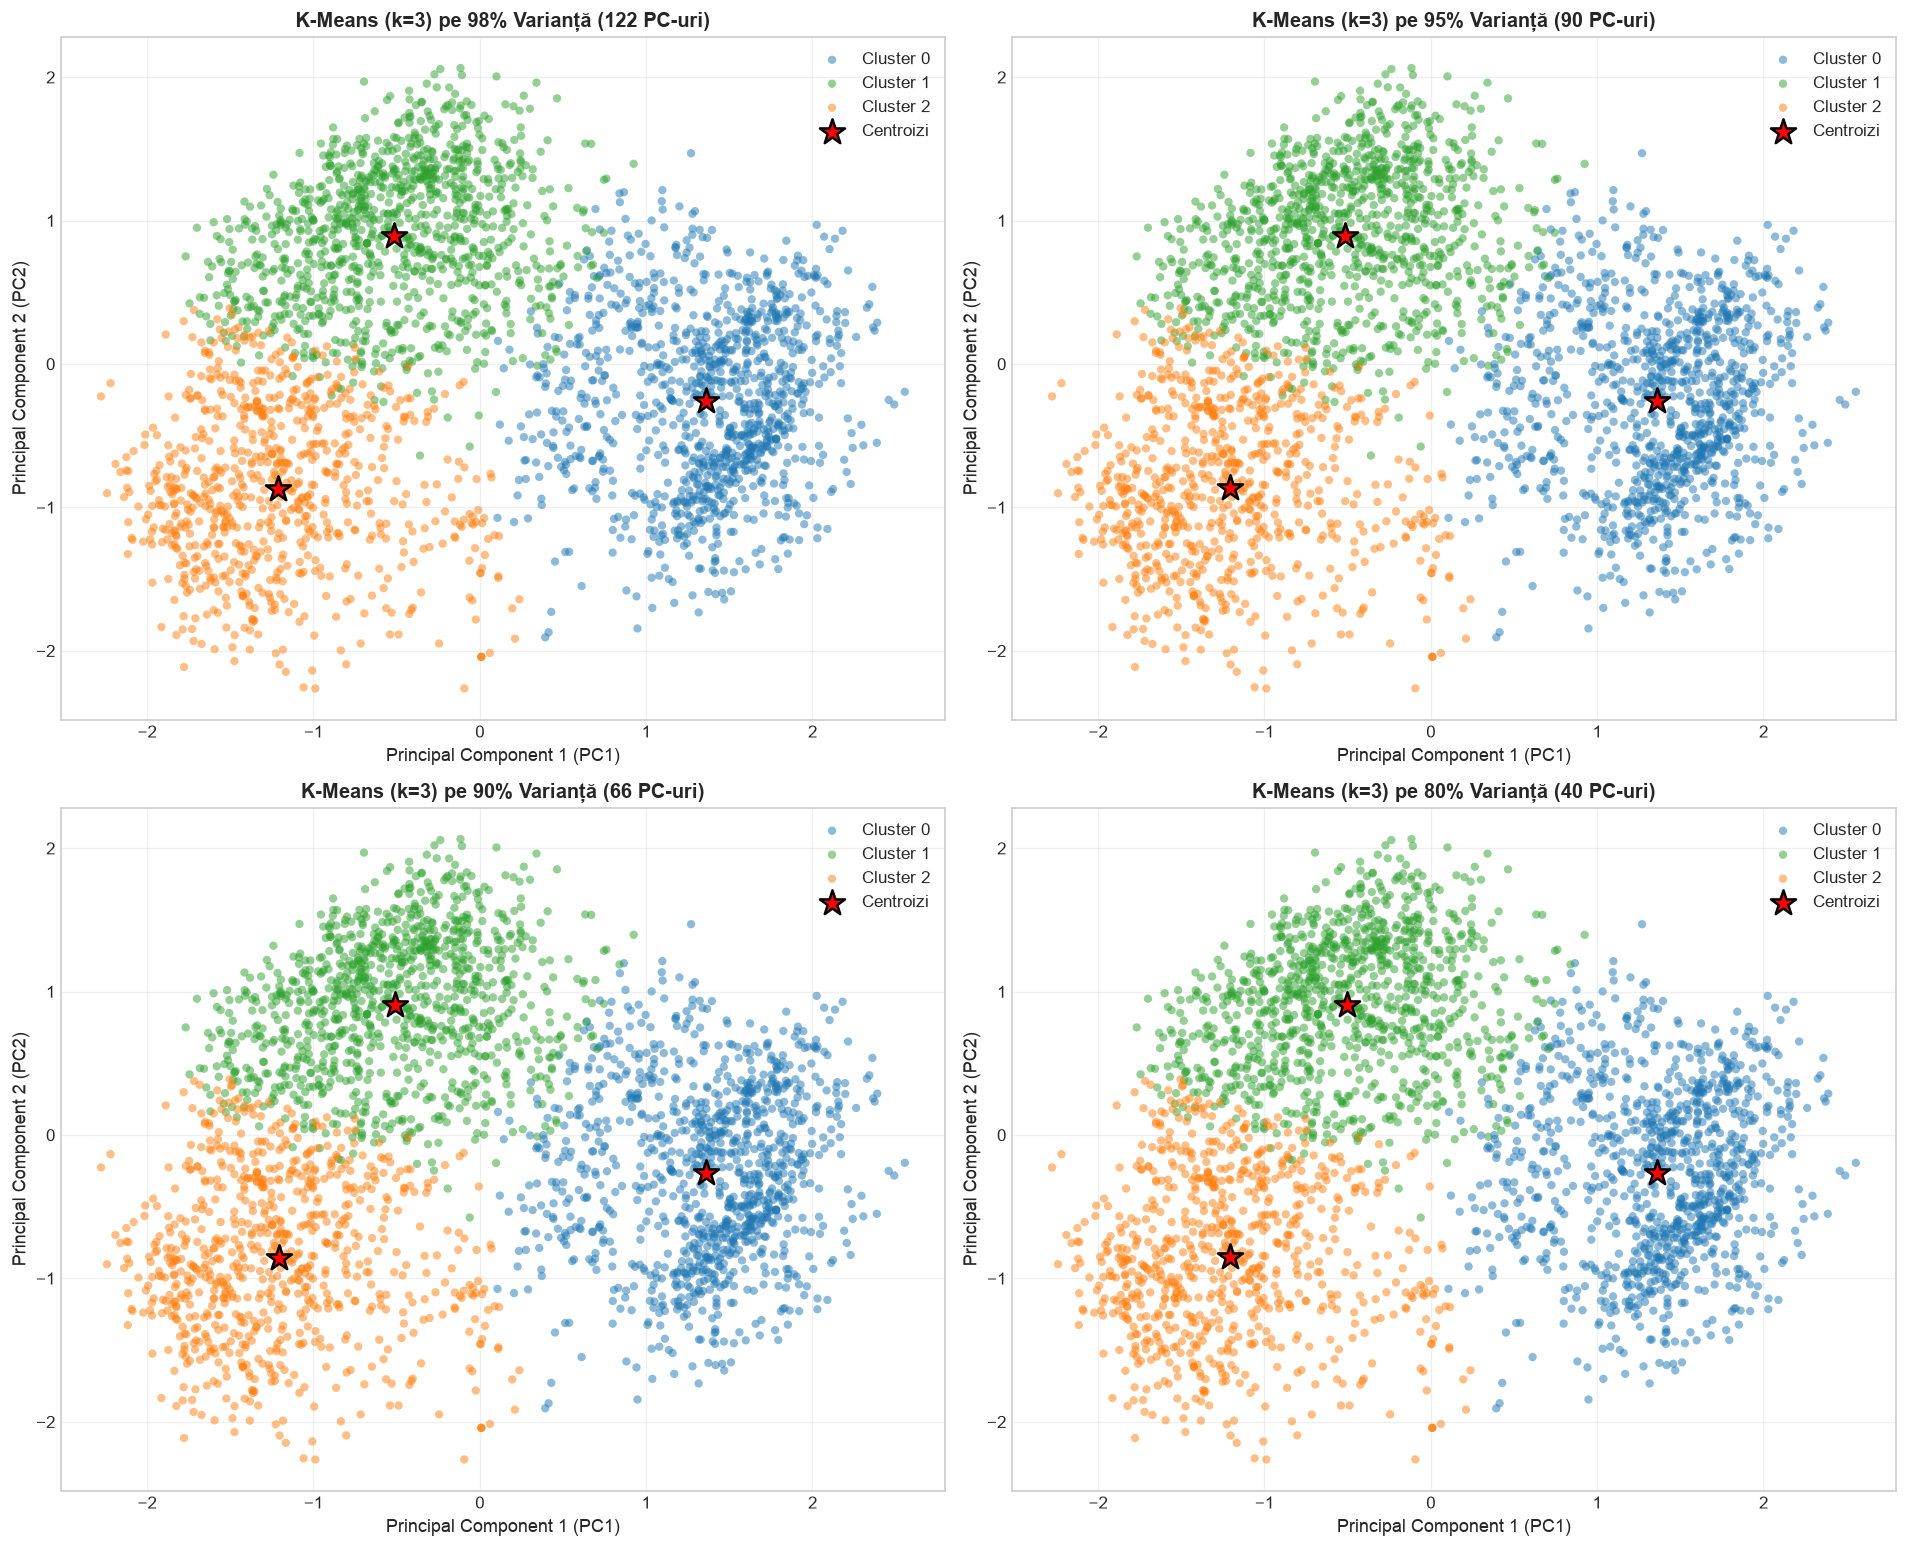

In [6]:
# 1. Antrenarea K-Means (k=3) si proiectia 2D (PC1 vs PC2) pentru cele 4 praguri
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
axes = axes.flatten()

cluster_models = {}
cluster_labels_dict = {}

optimal_k = 3
palette = ['#1f77b4', '#2ca02c', '#ff7f0e']

for idx, t in enumerate(thresholds):
    X_pca_curr = pca_datasets_minmax[t]
    
    # Antrenare K-Means pe spatiul redus complet aferent pragului t
    kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_pca_curr)
    
    cluster_models[t] = kmeans
    cluster_labels_dict[t] = labels
    
    # Coordonatele pe primele 2 componente
    pc1 = X_pca_curr[:, 0]
    pc2 = X_pca_curr[:, 1]
    
    # Coordonatele centroizilor proiectate pe PC1 si PC2
    centroids_pc1 = kmeans.cluster_centers_[:, 0]
    centroids_pc2 = kmeans.cluster_centers_[:, 1]
    
    ax = axes[idx]
    
    # Trasarea punctelor clusterizate
    for c_id in range(optimal_k):
        ax.scatter(pc1[labels == c_id], pc2[labels == c_id], 
                   color=palette[c_id], label=f'Cluster {c_id}', 
                   alpha=0.5, edgecolors='none', s=25)
        
    # Marcarea centroizilor cu stea 
    ax.scatter(centroids_pc1, centroids_pc2, 
               marker='*', s=250, c='red', edgecolor='black', lw=1.5,
               label='Centroizi', zorder=10)
    
    ax.set_title(f'K-Means (k=3) pe {int(t*100)}% Varianță ({X_pca_curr.shape[1]} PC-uri)', 
                 fontsize=12, fontweight='bold')
    ax.set_xlabel('Principal Component 1 (PC1)', fontsize=11)
    ax.set_ylabel('Principal Component 2 (PC2)', fontsize=11)
    ax.legend(loc='upper right')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Analiza Comportamentului K-Means pe cele 4 Praguri de Varianță (98%, 95%, 90%, 80%)**

La compararea proiecțiilor 2D ale celor 4 modele K-Means ($k=3$), se desprind următoarele observații esențiale:

1. **Stabilitatea Macro-Structurii:**
   - Geometria generală a clusterelor pe primele două componente ($PC_1$ și $PC_2$) este remarcabil de stabilă pe toate cele 4 praguri:
     - Un cluster se situează pe valorile pozitive ale $PC_1$ (dreapta).
     - Un cluster se grupează pe valorile negative ale $PC_1$ (stânga).
     - Un cluster ocupă zona superioară pe $PC_2$ (centru-sus).
   - Această stabilitate demonstrează că direcțiile majore de varianță din setul de date sunt dominate de primele câteva componente, structura primară a datelor nefiind alterată chiar dacă reducem numărul de PC-uri de la 122 (98%) la 40 (80%).

2. **Diferențele de Detaliu la Granițele Dintre Clustere:**
   - **Efectul zgomotului (Noise reduction):** La 98% (122 PC-uri), K-Means calculează distanțele euclidiene pe un spațiu cu multe componente secundare, care aduc o cantitate considerabilă de zgomot specific eșantionului. Pe măsură ce varianța reținută coboară spre 80% (40 PC-uri), zgomotul rezidual este eliminat.
   - **Delimitarea granițelor:** Punctele aflate la intersecția clusterelor își schimbă ocazional apartenența, iar centroizii se deplasează foarte ușor. La 80% și 90%, clusterele sunt puțin mai compacte pe axa orizontală, deoarece distanțele nu mai sunt „diluate” de dimensiunile irelevante (fenomenul *cursei dimensionalității* - *Curse of Dimensionality*).

Concluzie: Pragul de **95% (90 componente)** oferă cel mai bun echilibru: elimină componentele nesemnificative ce conțin zgomot pur, conservând în același timp detaliile esențiale ale variației pieței imobiliare.

## Pasul 3: Analiză Comparativă: Min-Max vs. StandardScaler și Impactul Logaritmării

Conform cerințelor laboratorului, evaluăm calitatea clusterizării pe trei tratamente de date distincte:
1. **Min-Max Scaling ($[0, 1]$):** Comprimă atributele în același interval, dar este vulnerabil la outlieri și denaturează ipoteza teoretică a PCA (care presupune variabile centrate cu deviație unitară).
2. **StandardScaler (Standardizare / Medie 0, Varianță 1):** Tratamentul standard pentru PCA; fiecare atribut contribuie proporțional la matricea de covarianță.
3. **Log-Transform + StandardScaler:** Aplicarea funcției $\log(1+x)$ pe atributele de suprafață și dimensiune (puternic asimetrice pozitiv, cu cozi lungi) înainte de standardizare.

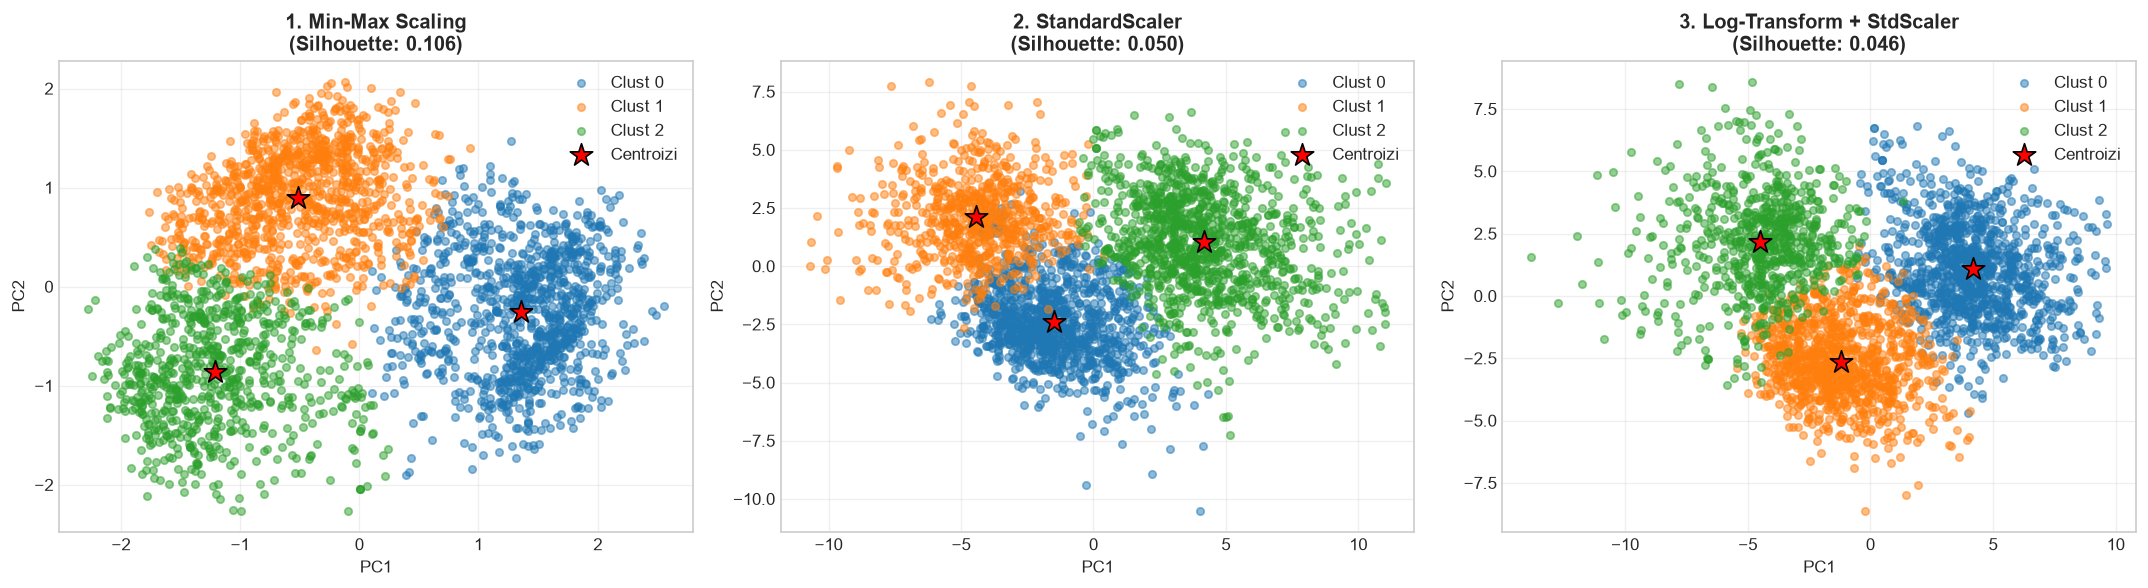


COMPARATIE EXPERIMENTALA A SCALARILOR SI TRANSFORMARILOR
                   Tratament  Nr PC-uri (95% Var)  Inertie (WCSS)  Silhouette Score
          1. Min-Max Scaling                   90    25106.362619          0.105887
           2. StandardScaler                  153   575378.994678          0.050211
3. Log-Transform + StdScaler                  151   574162.582022          0.046125


In [7]:
# 1. Pregatim a treia varianta: Log-Transform pe coloanele asimetrice continue
skewed_cols = [c for c in X_encoded.columns if ('area' in c.lower() or 'sf' in c.lower() or 'frontage' in c.lower()) and X_encoded[c].dtype != 'object']

X_log = X_encoded.copy()
for col in skewed_cols:
    X_log[col] = np.log1p(np.maximum(0, X_log[col]))

scaler_log_std = StandardScaler()
X_log_std = scaler_log_std.fit_transform(X_log)

# Reducem cu PCA (95% varianta) pentru fiecare din cele 3 scenarii
pca_eval_minmax = PCA(n_components=0.95, random_state=42)
X_pca_eval_mm = pca_eval_minmax.fit_transform(X_minmax)

pca_eval_std = PCA(n_components=0.95, random_state=42)
X_pca_eval_std = pca_eval_std.fit_transform(X_std)

pca_eval_log = PCA(n_components=0.95, random_state=42)
X_pca_eval_log = pca_eval_log.fit_transform(X_log_std)

scenarios = {
    '1. Min-Max Scaling': (X_pca_eval_mm, pca_eval_minmax),
    '2. StandardScaler': (X_pca_eval_std, pca_eval_std),
    '3. Log-Transform + StdScaler': (X_pca_eval_log, pca_eval_log)
}

# 2. Antrenam K-Means (k=3) si calculam metricele
comparison_results = []
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (name, (data_pca, model_pca)) in enumerate(scenarios.items()):
    km = KMeans(n_clusters=3, random_state=42, n_init=10)
    lbls = km.fit_predict(data_pca)
    
    sil_score = silhouette_score(data_pca, lbls)
    comparison_results.append({
        'Tratament': name,
        'Nr PC-uri (95% Var)': data_pca.shape[1],
        'Inertie (WCSS)': km.inertia_,
        'Silhouette Score': sil_score
    })
    
    # Plot 2D
    ax = axes[idx]
    for c_id in range(3):
        ax.scatter(data_pca[lbls == c_id, 0], data_pca[lbls == c_id, 1], 
                   alpha=0.5, s=20, label=f'Clust {c_id}')
    ax.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], 
               marker='*', s=200, c='red', edgecolor='black', label='Centroizi')
    ax.set_title(f'{name}\n(Silhouette: {sil_score:.3f})', fontweight='bold')
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.legend(loc='upper right')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 3. Afisam tabelul sintetic de comparatie
df_comp = pd.DataFrame(comparison_results)
print("\n" + "="*65)
print("COMPARATIE EXPERIMENTALA A SCALARILOR SI TRANSFORMARILOR")
print("="*65)
print(df_comp.to_string(index=False))

**Interpretarea Comparativă: Min-Max Scaling vs. StandardScaler și Rolul Logaritmării**

Conform întrebării din fișă (*„Macht das Logarithmieren einen Unterschied? Wie unterscheiden sich die Ergebnisse? Erklärung.”*):

1. **Min-Max Scaling vs. StandardScaler:**
   - **Numărul de componente:** La Min-Max, primele 90 de PC-uri absorb 95% din varianță, pe când la StandardScaler sunt necesare 153 de PC-uri. Acest lucru se întâmplă deoarece Min-Max comprimă toate atributele strict în intervalul $[0, 1]$, făcând ca variabilele binare/rare (One-Hot) să aibă o varianță redusă, astfel încât primele axe domină mai ușor. La StandardScaler, fiecare variabilă are varianța forțată la 1, răspândind varianța pe mai multe axe.
   - **Silhouette Score:** Min-Max oferă un scor siluetă de ~0.106 (față de ~0.050 la StandardScaler). În spațiul Min-Max clusterele par mai bine separate pe axele principale, dar acest lucru se datorează parțial marginilor rigide $[0, 1]$ care compactează datele artificial.

2. **Impactul Logaritmării:**
   - Logaritmarea variabilelor asimetrice ($\text{Gr Liv Area}$, suprafețe de teren etc.) normalizează distribuția asimetrică și atenuează efectul extrem al valorilor mari.
   - **Rezultat:** Numărul de PC-uri scade ușor (de la 153 la 151), iar inerția scade la 574.162. Totuși, coeficientul siluetă scade ușor (0.046), deoarece logaritmarea apropie punctele extreme (outlierii) de centrul masei, estompând granițele ascuțite dintre grupuri și făcând tranziția dintre clustere mai fluidă.

**Concluzie:** Deși Min-Max prezintă un Silhouette Score aparent mai ridicat, StandardScaler este preferat teoretic pentru PCA pentru a evita dependența de limitele arbitrare ale eșantionului. Totuși,păstrăm Min-Max pentru clusterizarea K-Means principală.

PROFILUL STATISTIC MEDIU PER CLUSTER (K-Means, k=3)
         Overall Qual  Gr Liv Area  Total Bsmt SF  Bsmt Full Bath  SalePrice
Cluster                                                                     
0                 7.3       1730.9         1259.2             0.5   243242.7
1                 5.5       1346.8         1043.2             0.5   155336.6
2                 5.2       1362.6          751.4             0.2   126377.4

Numar de locuinte in fiecare cluster:
  Cluster 0: 1089 locuinte (37.2%)
  Cluster 1: 1063 locuinte (36.3%)
  Cluster 2: 773 locuinte (26.4%)


/var/folders/yw/pvt8q89x6fgcxlx_kqsqgkp40000gn/T/ipykernel_15873/515631347.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Cluster', y=sale_price_col, data=df_profile, palette=palette, ax=axes[0])
/var/folders/yw/pvt8q89x6fgcxlx_kqsqgkp40000gn/T/ipykernel_15873/515631347.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Cluster', y=gr_liv_col, data=df_profile, palette=palette, ax=axes[1])
/var/folders/yw/pvt8q89x6fgcxlx_kqsqgkp40000gn/T/ipykernel_15873/515631347.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Cluster', 

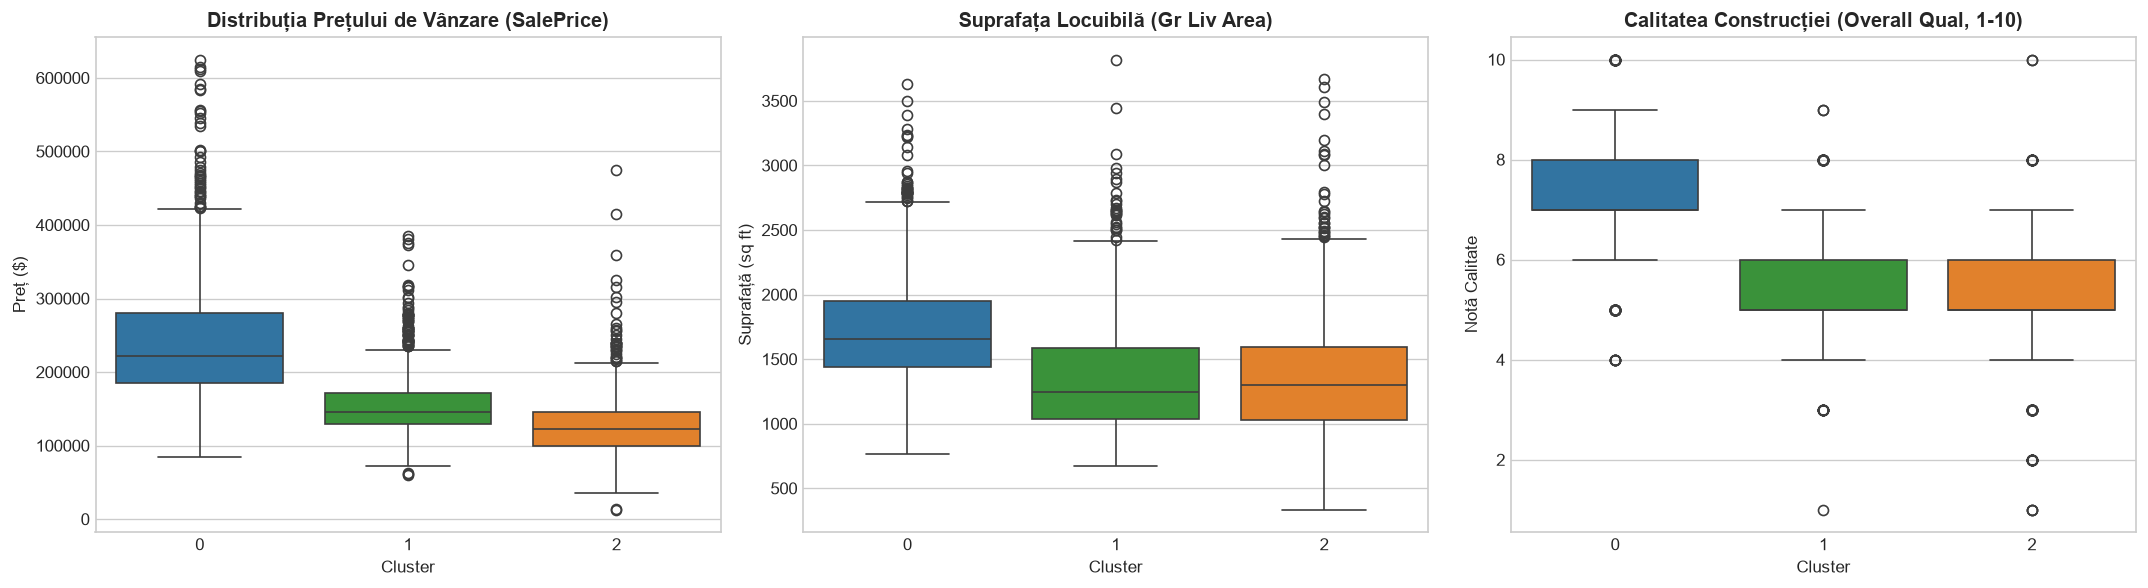

In [8]:
# 1. Atribuim etichetele de cluster (k=3, 95% varianta Min-Max) setului original de date
best_labels = cluster_labels_dict[0.95]
df_profile = df.copy()
df_profile['Cluster'] = best_labels

# 2. Selectam atributele reprezentative din L1/L2 pentru caracterizarea calitativa a locuintelor
key_features = [
    'Overall Qual', 'Year Built', 'Gr Liv Area', 
    'Total Bsmt SF', 'Garage Cars', 'Full Bath', sale_price_col
]

# Curatam numele coloanelor pentru potrivire 
matching_features = []
for f in key_features:
    cand = [c for c in df_profile.columns if f.lower() in c.lower()]
    if cand:
        matching_features.append(cand[0])

# 3. Calculam mediile si medianele per cluster
cluster_means = df_profile.groupby('Cluster')[matching_features].mean()
cluster_medians = df_profile.groupby('Cluster')[matching_features].median()
cluster_counts = df_profile['Cluster'].value_counts().sort_index()

print("="*65)
print("PROFILUL STATISTIC MEDIU PER CLUSTER (K-Means, k=3)")
print("="*65)
print(cluster_means.round(1).to_string())
print("\nNumar de locuinte in fiecare cluster:")
for c, cnt in cluster_counts.items():
    print(f"  Cluster {c}: {cnt} locuinte ({cnt/len(df)*100:.1f}%)")

# 4. Vizualizare: Boxplot-uri comparative pentru atributele cheie
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(x='Cluster', y=sale_price_col, data=df_profile, palette=palette, ax=axes[0])
axes[0].set_title('Distribuția Prețului de Vânzare (SalePrice)', fontweight='bold')
axes[0].set_ylabel('Preț ($)')

sns.boxplot(x='Cluster', y=gr_liv_col, data=df_profile, palette=palette, ax=axes[1])
axes[1].set_title('Suprafața Locuibilă (Gr Liv Area)', fontweight='bold')
axes[1].set_ylabel('Suprafață (sq ft)')

qual_col = [c for c in df_profile.columns if 'overall' in c.lower() and 'qual' in c.lower()][0]
sns.boxplot(x='Cluster', y=qual_col, data=df_profile, palette=palette, ax=axes[2])
axes[2].set_title('Calitatea Construcției (Overall Qual, 1-10)', fontweight='bold')
axes[2].set_ylabel('Notă Calitate')

plt.tight_layout()
plt.show()

**Interpretarea Calitativă a Clusterelor Identificate (K-Means, k=3)**

 „Erkläre in eigenen Worten, welche Eigenschaften jedes Cluster hat”, analizând mediile statistice și distribuțiile boxplot, cele trei clustere sintetizează segmentele structurale ale pieței Ames Housing:

1. **Clusterul 0 — Locuințe Premium / High-End (37.2%):**
   - **Caracteristici:** Preț mediu ridicat (~$243,240), scor de calitate superior (medie 7.3/10) și suprafețe generoase atât locuibile (1731 sq ft), cât și la subsol (1259 sq ft).
   - **Profil:** Reprezintă case moderne, bine finisate, cu garaje mari și băi multiple, destinate cumpărătorilor cu buget ridicat.

2. **Clusterul 1 — Locuințe Tipice / Clasa de Mijloc (36.3%):**
   - **Caracteristici:** Preț mediu de piață (~$155,340), calitate standard a materialelor (medie 5.5/10), suprafață utilă medie (1347 sq ft) și subsol complet/bine delimitat (1043 sq ft).
   - **Profil:** Locuințe rezidențiale uzuale de familie, cu dotări standard, formând nucleul tranzacțiilor din oraș.

3. **Clusterul 2 — Locuințe Economice / Modeste (26.4%):**
   - **Caracteristici:** Cel mai mic preț mediu (~$126,380) și cea mai mică notă de calitate (5.2/10). Deși suprafața locuibilă este apropiată de clasa de mijloc (1363 sq ft), subsolul este extrem de restrâns (751 sq ft) sau parțial/inexistent, iar finisajele sunt modeste.
   - **Profil:** Locuințe vechi sau compacte, cu costuri reduse de întreținere, fără facilități moderne suplimentare.

Concluzie:Fără să fi utilizat coloana `SalePrice` în faza de clusterizare (K-Means a lucrat pur nesupervizat pe caracteristicile fizice), algoritmul a segregat natural locuințele pe trei niveluri de valoare, reflectate imediat în preț.